# Где теряется IoU

Разбор ошибок нарезки на всей валидации: чекпоинт прогона `RUN` (`RUN` в первой ячейке
кода) и текущая нарезка по
графу (водораздел по глубине, слияние с вето по эмбеддингу; README, «Голова границ»).

IoU детали — среднее IoU по её граням, поэтому недобор `1 − IoU` раскладывается по
граням точно: грань `f` на детали из `F` граней вносит `(1 − IoU_f) / F`. Суммы по
группам граней ниже и есть ответ на вопрос «где теряется IoU» — в пунктах итогового
IoU, а не в долях граней.

Потеряна — грань с IoU ниже 0.5. Грани мельче `MIN_FACE` треугольников в метрику не
входят, а регионы мельче `MIN_REGION` отдаются соседу: на 30 тысячах треугольников это
5 и 30, при другом разрешении — та же доля детали (на 60 тысячах 10 и 60), как в
обучении (первая ячейка кода).

Прогон задаётся в первой ячейке кода (`RUN`), его конфиг — разрешение, признаки, кэш —
берётся из `runs/<RUN>/train.sh`. Сменили прогон на другой конфиг — перезапустите ядро.
Кривые по эпохам читают только `log.json` и смотрятся на любой эпохе идущего прогона.

In [1]:
import json
import os
import sys
from collections import defaultdict
from pathlib import Path

ROOT = Path(os.path.expanduser("~/curv_ai_segm"))
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np

# Прогон: его best.pt разбирается по граням, его log.json даёт кривые по эпохам, его конфиг
# (из runs/<RUN>/train.sh) задаёт кэш. Ставится до импорта кода проекта.
RUN = "aug60w"
from src.runs import absorb_mm, run_flags, thresholds, use_run
CONFIG = use_run(RUN)
FLAGS = run_flags(RUN)                         # правило узких граней и сплиты прогона
NARROW = FLAGS["narrow"]
ABSORB_MM = absorb_mm(RUN)                     # разметка как в обучении прогона
CHECKPOINT = ROOT / "runs" / RUN / "best.pt"
SPLIT = FLAGS["val_split"]
LIMIT = None                                   # None — весь сплит
RECORDS = ROOT / "runs" / RUN / "face_records.json"      # кэш: удалить, чтобы пересчитать

# Пороги нарезки и метрики — под разрешение конфига, как в обучении (README, «Разрешение»).
# Разбор с другими порогами пишется в свой файл и не подхватывается молча.
from dataset.cache import CONFIG_TAG
MIN_FACE, PARTITION = thresholds()
MIN_REGION = PARTITION.min_region
if (MIN_FACE, MIN_REGION) != (5, 30):
    RECORDS = RECORDS.with_name(f"face_records.mf{MIN_FACE}_mr{MIN_REGION}.json")
if ABSORB_MM:
    RECORDS = RECORDS.with_name(RECORDS.stem + f".absorb{ABSORB_MM:g}.json")
RECORDS = RECORDS.with_name(RECORDS.stem + (".narrow" if NARROW else "") + ".exact.json")
print(f"прогон {RUN}, конфиг {CONFIG.name}, грани от {MIN_FACE} треугольников, "
      f"поглощение регионов мельче {MIN_REGION}, скругления и фаски до {ABSORB_MM:g} мм — соседям, "
      f"правило узких граней {'да' if NARROW else 'нет'}, сплит {SPLIT}")
# Полосы точной полуширины, мм (README, «Узкие грани: ширина в мм и правило разметки»).
WIDTH_BANDS = [("≤0.5 мм", -1, 0.5), ("0.5–1 мм", 0.5, 1.0), ("1–3 мм", 1.0, 3.0), (">3 мм", 3.0, np.inf)]

TYPES = ["plane", "cylinder", "cone", "sphere", "torus", "bspline"]
# Категориальная палитра, фиксированный порядок (проверена на различимость соседних пар).
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
GRAY, INK, INK2 = "#b8b7b1", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": INK2,
    "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})

прогон aug60w, конфиг aug60w.yaml, грани от 10 треугольников, поглощение регионов мельче 60, скругления и фаски до 2 мм — соседям, правило узких граней нет, сплит val


## Состав датасета

Грани рабочих мешей варианта `noisy` по сплитам: по типу поверхности, по размеру
в треугольниках и по точной полуширине (из B-Rep, у деталей без неё — «нет данных»). От прогона не зависит; считается по всему
корпусу несколько минут и кэшируется в `FACE_STATS`.

In [2]:
# Своя у каждого кэша: сводка по граням корпуса зависит от разрешения и подложки.
FACE_STATS = ROOT / "dataset" / "data" / (f"face_stats.{CONFIG_TAG}" if CONFIG_TAG else "face_stats")
FACE_STATS = FACE_STATS.with_name(FACE_STATS.name + f".{FLAGS['val_split']}" + (".narrow" if NARROW else "") + ".exact.npz")
SPLIT_NAMES = (FLAGS["train_split"], FLAGS["val_split"], FLAGS["val_split"].replace("val", "test"))

def part_faces(uid):
    """(тип, треугольников, полуширина в мм) на каждую грань детали."""
    from dataset.cache import part_dir
    from src.data import exact_halfwidth, face_types, narrow_groups, relabel
    z = np.load(part_dir(uid, "noisy") / "work.npz")
    labels = z["labels"].astype(np.int64)
    n = int(labels.max()) + 1
    types = face_types(uid, n)[labels]
    remap = np.arange(n)
    if NARROW:
        group, drop = narrow_groups(uid, n)
        if drop.any() or (group != np.arange(n)).any():
            labels, remap = relabel(labels, z["adjacency"].astype(np.int64), group, drop)
    m = int(labels.max()) + 1
    tri = np.bincount(labels, minlength=m)
    t = np.full(m, -1); t[labels] = types
    rows = np.stack([t, tri, exact_halfwidth(uid, remap, m)], 1)
    return rows[tri > 0]

if FACE_STATS.exists():
    stats = dict(np.load(FACE_STATS))
else:
    from multiprocessing import Pool
    from src.data import split_uids
    # Кэш собирается не на все сплиты (у aug60w нет test): пустые пропускаются.
    uids = {s: split_uids(s, "noisy") for s in SPLIT_NAMES}
    with Pool(16) as pool:
        stats = {s: np.concatenate(pool.map(part_faces, u, chunksize=20)) for s, u in uids.items() if u}
    np.savez(FACE_STATS, **stats)
SPLITS = tuple(stats)

from IPython.display import Markdown, display
from src.model import PRIMITIVE_TYPES

def table(title, groups):
    cols = [stats[s] for s in SPLITS] + [np.concatenate([stats[s] for s in SPLITS])]
    lines = [f"**{title}**", "", "| | " + " | ".join(SPLITS) + " | всего |", "|---" * (len(SPLITS) + 2) + "|"]
    for name, fn in groups + [("всего", lambda r: np.ones(len(r), bool))]:
        lines.append(f"| {name} | " + " | ".join(f"{int(fn(r).sum()):,} ({fn(r).mean():.1%})".replace(",", " ") for r in cols) + " |")
    display(Markdown("\n".join(lines)))

table("По типу поверхности", [(t, lambda r, i=i: r[:, 0] == i) for i, t in enumerate(PRIMITIVE_TYPES)])
edges = [1, MIN_FACE, 20, 50, 150, 500, 2000, None]
table("По размеру, треугольников", [(f"{lo}–{hi - 1}" if hi else f"{lo}+", lambda r, lo=lo, hi=hi: (r[:, 1] >= lo) & (r[:, 1] < (hi or np.inf)))
                                   for lo, hi in zip(edges[:-1], edges[1:])])
table("По точной полуширине", [(name, lambda r, lo=lo, hi=hi: (r[:, 2] > lo) & (r[:, 2] <= hi)) for name, lo, hi in WIDTH_BANDS]
      + [("нет данных", lambda r: np.isnan(r[:, 2]))])
print(f"грани мельче {MIN_FACE} треугольников в метрики не входят; медиана треугольников на грань:",
      {s: int(np.median(stats[s][:, 1])) for s in SPLITS})

**По типу поверхности**

| | train | val | всего |
|---|---|---|---|
| plane | 31 531 (54.6%) | 7 705 (53.5%) | 39 236 (54.4%) |
| cylinder | 15 680 (27.2%) | 4 124 (28.6%) | 19 804 (27.4%) |
| cone | 1 360 (2.4%) | 309 (2.1%) | 1 669 (2.3%) |
| sphere | 548 (0.9%) | 132 (0.9%) | 680 (0.9%) |
| torus | 1 994 (3.5%) | 518 (3.6%) | 2 512 (3.5%) |
| bspline | 6 639 (11.5%) | 1 611 (11.2%) | 8 250 (11.4%) |
| всего | 57 752 (100.0%) | 14 399 (100.0%) | 72 151 (100.0%) |

**По размеру, треугольников**

| | train | val | всего |
|---|---|---|---|
| 1–9 | 1 259 (2.2%) | 262 (1.8%) | 1 521 (2.1%) |
| 10–19 | 801 (1.4%) | 176 (1.2%) | 977 (1.4%) |
| 20–49 | 2 003 (3.5%) | 564 (3.9%) | 2 567 (3.6%) |
| 50–149 | 4 935 (8.5%) | 1 306 (9.1%) | 6 241 (8.6%) |
| 150–499 | 11 592 (20.1%) | 2 730 (19.0%) | 14 322 (19.9%) |
| 500–1999 | 20 335 (35.2%) | 5 152 (35.8%) | 25 487 (35.3%) |
| 2000+ | 16 827 (29.1%) | 4 209 (29.2%) | 21 036 (29.2%) |
| всего | 57 752 (100.0%) | 14 399 (100.0%) | 72 151 (100.0%) |

**По точной полуширине**

| | train | val | всего |
|---|---|---|---|
| ≤0.5 мм | 0 (0.0%) | 0 (0.0%) | 0 (0.0%) |
| 0.5–1 мм | 0 (0.0%) | 0 (0.0%) | 0 (0.0%) |
| 1–3 мм | 0 (0.0%) | 0 (0.0%) | 0 (0.0%) |
| >3 мм | 0 (0.0%) | 0 (0.0%) | 0 (0.0%) |
| нет данных | 57 752 (100.0%) | 14 399 (100.0%) | 72 151 (100.0%) |
| всего | 57 752 (100.0%) | 14 399 (100.0%) | 72 151 (100.0%) |

грани мельче 10 треугольников в метрики не входят; медиана треугольников на грань: {'train': 914, 'val': 914}


### Рёбра по типу кривой

Рёбра B-Rep случайных 2000 деталей каждого корпуса, прямо по STEP, до слияния швов (этап 1
тип кривой ребра не хранит). Считает `scripts/edge_curves.py`, итог в
`dataset/data/edge_curves.<корпус>.json`. Шов — ребро, у которого с обеих сторон одна и та же
грань (замыкание цилиндра, сферы). Неаналитические поверхности (B-сплайн, выдавливание,
вращение, эквидистанта) сведены в `bspline`, как в обучении.

In [3]:
EDGE_CURVES = {c: ROOT / "dataset" / "data" / f"edge_curves.{c}.json" for c in ("fusion", "abc")}
CURVE_NAMES = {"line": "прямая", "circle": "окружность", "ellipse": "эллипс", "bsplinecurve": "B-сплайн",
               "beziercurve": "Безье", "offsetcurve": "эквидистанта", "othercurve": "прочая",
               "hyperbola": "гипербола", "parabola": "парабола"}
MAIN_CURVES = ["line", "circle", "bsplinecurve"]

def edge_table(corpus):
    d = json.loads(EDGE_CURVES[corpus].read_text())
    kind = np.array([e[0] for p in d["parts"] for e in p["edges"]])
    length = np.array([e[1] for p in d["parts"] for e in p["edges"]])
    surf = lambda s: s if s in TYPES else "bspline"
    joint = np.array(["шов: " + surf(e[2][0]) if len(e[2]) == 1 else "–".join(sorted(surf(s) for s in e[2]))
                      for p in d["parts"] for e in p["edges"]])
    n, total = len(kind), length.sum()
    lines = [f"**{corpus}**: {len(d['parts'])} деталей из {d['of']}, рёбер {n:,}".replace(",", " "), "",
             "| кривая | доля рёбер | доля длины | медиана длины, мм | короче 0.1 мм |", "|---|---|---|---|---|"]
    for k in sorted(set(kind), key=lambda k: -(kind == k).sum()):
        m = kind == k
        lines.append(f"| {CURVE_NAMES.get(k, k)} | {m.mean():.1%} | {length[m].sum() / total:.1%} | "
                     f"{np.median(length[m]):.2f} | {(length[m] < 0.1).mean():.1%} |")
    lines += ["", "| стык (поверхности по сторонам) | доля рёбер | " +
              " | ".join(CURVE_NAMES[k] for k in MAIN_CURVES) + " | прочие |", "|---" * (len(MAIN_CURVES) + 3) + "|"]
    pairs, counts = np.unique(joint, return_counts=True)
    for pr in pairs[np.argsort(-counts)][:15]:
        m = joint == pr
        shares = [(kind[m] == k).mean() for k in MAIN_CURVES]
        lines.append(f"| {pr} | {m.mean():.1%} | " + " | ".join(f"{s:.0%}" for s in shares) + f" | {1 - sum(shares):.0%} |")
    display(Markdown("\n".join(lines)))

for corpus in EDGE_CURVES:
    if EDGE_CURVES[corpus].exists():
        edge_table(corpus)
    else:
        print(f"нет {EDGE_CURVES[corpus].name}: python scripts/edge_curves.py --corpus {corpus}")


**fusion**: 2000 деталей из 11826  рёбер 129 575

| кривая | доля рёбер | доля длины | медиана длины, мм | короче 0.1 мм |
|---|---|---|---|---|
| прямая | 61.8% | 55.4% | 2.56 | 2.3% |
| окружность | 26.1% | 37.2% | 2.52 | 2.8% |
| B-сплайн | 10.7% | 6.7% | 2.31 | 3.0% |
| эллипс | 1.4% | 0.7% | 1.00 | 6.5% |

| стык (поверхности по сторонам) | доля рёбер | прямая | окружность | B-сплайн | прочие |
|---|---|---|---|---|---|
| plane–plane | 39.1% | 100% | 0% | 0% | 0% |
| cylinder–plane | 29.9% | 42% | 56% | 0% | 2% |
| bspline–plane | 8.5% | 13% | 3% | 82% | 2% |
| шов: cylinder | 3.7% | 100% | 0% | 0% | 0% |
| bspline–bspline | 3.4% | 77% | 5% | 17% | 0% |
| cylinder–cylinder | 2.8% | 52% | 0% | 30% | 18% |
| cylinder–torus | 2.6% | 0% | 89% | 11% | 0% |
| cone–plane | 1.8% | 25% | 47% | 28% | 0% |
| plane–torus | 1.8% | 0% | 83% | 17% | 0% |
| bspline–cylinder | 1.6% | 13% | 40% | 37% | 10% |
| cylinder–sphere | 1.2% | 0% | 99% | 1% | 0% |
| cone–cylinder | 0.9% | 0% | 80% | 20% | 0% |
| шов: torus | 0.6% | 0% | 100% | 0% | 0% |
| шов: cone | 0.5% | 100% | 0% | 0% | 0% |
| cone–torus | 0.3% | 0% | 99% | 1% | 0% |

**abc**: 2000 деталей из 208091  рёбер 302 558

| кривая | доля рёбер | доля длины | медиана длины, мм | короче 0.1 мм |
|---|---|---|---|---|
| прямая | 57.7% | 69.8% | 5.50 | 1.1% |
| окружность | 24.0% | 21.0% | 6.28 | 0.7% |
| B-сплайн | 16.4% | 8.5% | 2.54 | 1.0% |
| эллипс | 1.9% | 0.6% | 2.85 | 1.5% |

| стык (поверхности по сторонам) | доля рёбер | прямая | окружность | B-сплайн | прочие |
|---|---|---|---|---|---|
| plane–plane | 40.2% | 98% | 0% | 2% | 0% |
| cylinder–plane | 29.8% | 42% | 53% | 2% | 3% |
| bspline–plane | 7.5% | 15% | 2% | 80% | 3% |
| cylinder–cylinder | 3.2% | 58% | 0% | 25% | 18% |
| bspline–bspline | 3.0% | 68% | 6% | 26% | 0% |
| шов: cylinder | 3.0% | 0% | 0% | 99% | 1% |
| cylinder–torus | 2.5% | 0% | 89% | 11% | 0% |
| bspline–cylinder | 2.1% | 14% | 24% | 51% | 11% |
| cone–plane | 1.7% | 17% | 48% | 34% | 1% |
| plane–torus | 1.7% | 0% | 81% | 19% | 0% |
| cylinder–sphere | 1.1% | 0% | 98% | 2% | 0% |
| cone–cylinder | 1.1% | 0% | 72% | 28% | 0% |
| шов: cone | 0.6% | 0% | 1% | 99% | 0% |
| bspline–torus | 0.5% | 0% | 43% | 57% | 0% |
| cone–cone | 0.3% | 19% | 56% | 25% | 0% |

## Сбор записей по граням

Один проход сети и нарезки по сплиту, около семи минут; результат кэшируется в
`face_records.json`. Для каждой потерянной грани — этап, на котором она потеряна:
водораздел (своего региона не было), агломерация (регион был, но слит) или отдача
мелких регионов соседу.

In [4]:
def collect():
    import scipy.sparse as sp
    import torch
    import torch.nn.functional as F
    import trimesh
    sys.path.insert(0, str(ROOT / "scripts")); sys.path.insert(0, str(ROOT / "scripts" / "boundary"))
    import train_boundary as bt
    from dataset.cache import load_part
    from src.boundary import partition as P
    from src.boundary.config import BCFG
    from src.boundary.model import BoundarySegNet, boundary_strength, head_config
    from src.config import CFG
    from src.data import PARTS, CachedParts, split_uids
    from src.fitting import absorb_small
    from src.metrics import face_halfwidth
    from src.model import PRIMITIVE_TYPES

    cfg = BCFG.partition
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    gen = torch.Generator(device=dev).manual_seed(0)
    st = torch.load(CHECKPOINT, map_location=dev)
    model = BoundarySegNet(st["channels"], CFG.model.emb_size, head_config(BCFG.model, st["model"])).to(dev)
    model.load_state_dict(st["model"]); model.eval()
    parts = CachedParts(split_uids(SPLIT, "noisy")[:LIMIT], "noisy", absorb_mm=ABSORB_MM, narrow=NARROW)

    def table(gt, lab):
        nl, npd = gt.max() + 1, lab.max() + 1
        return np.bincount(gt * npd + lab, minlength=nl * npd).reshape(nl, npd).astype(float)

    rows = []
    with torch.no_grad():
        for i in range(len(parts)):
            item = parts[i]; b = bt.build_batch(item, dev, gen)
            emb, logits, edge = model(b["x"], b["idx"], b["edges"])
            e = b["edges"].cpu().numpy().astype(np.int64); n = b["x"].shape[2]
            s = boundary_strength(edge)
            z = F.normalize(emb[0].t(), dim=1).double().cpu().numpy()
            gt = item["labels"].astype(np.int64)
            ws = P.watershed(n, e, s, cfg.depth)
            ag = P.agglomerate(ws, e, s, cfg.merge, z, cfg.veto)
            fin = np.unique(absorb_small(ag, e, MIN_REGION), return_inverse=True)[1]

            work = load_part(item["uid"], "noisy")["work"]
            mesh = trimesh.Trimesh(work["vertices"], work["faces"], process=False)
            edge_mm = float(np.median(mesh.edges_unique_length))
            area = np.bincount(gt, weights=mesh.area_faces)
            same = gt[e[:, 0]] == gt[e[:, 1]]
            A = sp.csr_matrix((np.ones(2 * same.sum()), (np.r_[e[same, 0], e[same, 1]], np.r_[e[same, 1], e[same, 0]])),
                              shape=(n, n))
            width = item["halfwidth_mm"]           # точная, из B-Rep; NaN — нет данных
            # граф меша порван — признак сломанного упрощения (README, «Пересборка на 60 тысяч»)
            G = sp.csr_matrix((np.ones(len(e)), (e[:, 0], e[:, 1])), shape=(n, n))
            broken = sp.csgraph.connected_components(G, directed=False)[0] > 1

            # Метки кэша → метки обучения (поглощённые скругления и фаски, перенумерация):
            # грань B-Rep → merge_map → метка кэша → remap. Тип грани — как в обучении.
            remap = item["remap"]
            ftype = {int(l): PRIMITIVE_TYPES[int(t)] for l, t in zip(gt, item["types"]) if t >= 0}
            brep = json.loads((PARTS / item["uid"] / "brep.json").read_text())
            mm = brep["merge_map"] or list(range(brep["n_faces"]))
            lab = lambda f: remap[mm[f]] if mm[f] < len(remap) else -1
            tang = set()
            for p_ in brep["adjacency"]:
                a_, b_ = lab(p_["a"]), lab(p_["b"])
                if p_["tangential"] and a_ != b_ and a_ >= 0 and b_ >= 0:
                    tang |= {int(a_), int(b_)}

            big = np.bincount(gt)[gt] >= MIN_FACE
            g = gt[big]
            Mf, Mw, Ma = table(g, fin[big]), table(g, ws[big]), table(g, ag[big])
            nf = Mf.sum(1)
            def iou_of(M):
                return (M / np.maximum(M.sum(1)[:, None] + M.sum(0)[None] - M, 1)).max(1)
            iou, iou_w, iou_a = iou_of(Mf), iou_of(Mw), iou_of(Ma)
            cb = Mf.argmax(1); owner = Mf.argmax(0)
            pur = Mf[np.arange(len(nf)), cb] / np.maximum(Mf.sum(0)[cb], 1)
            cov = Mf[np.arange(len(nf)), cb] / np.maximum(nf, 1)
            pur_w = Mw[np.arange(len(nf)), Mw.argmax(1)] / np.maximum(Mw.sum(0)[Mw.argmax(1)], 1)
            alive = np.nonzero(nf > 0)[0]
            for f in alive:
                lost = iou[f] < 0.5
                fate = "цела" if not lost else ("поглощена" if pur[f] < 0.5 else ("раздроблена" if cov[f] < 0.5 else "прочее"))
                stage = "" if not lost else ("водораздел" if (iou_w[f] < 0.5 and pur_w[f] < 0.5)
                                              else ("агломерация" if iou_a[f] < 0.5 else "мелкие регионы"))
                eater = int(owner[cb[f]]) if fate == "поглощена" else -1
                rows.append(dict(uid=item["uid"], face=int(f), faces_in_part=int(len(alive)), broken=bool(broken),
                                 tri=int(nf[f]), area_mm2=float(area[f]), width_mm=float(width[f]),
                                 type=ftype.get(int(f), "?"), tangent=int(f) in tang, iou=float(iou[f]),
                                 lost=bool(lost), fate=fate, stage=stage,
                                 eater_type=ftype.get(eater, "?") if eater >= 0 else ""))
            if (i + 1) % 200 == 0:
                print(f"{i + 1}/{len(parts)}", flush=True)
    RECORDS.write_text(json.dumps(rows, ensure_ascii=False))
    return rows

rows = json.loads(RECORDS.read_text()) if RECORDS.exists() else collect()
col = {k: np.array([r[k] for r in rows]) for k in rows[0]}
n_parts = len(set(col["uid"]))
# вклад грани в недобор IoU: (1 − IoU) / число граней детали / число деталей
col["deficit"] = (1 - col["iou"]) / col["faces_in_part"] / n_parts
part_iou = {}
for u, v in zip(col["uid"], col["iou"]):
    part_iou.setdefault(u, []).append(v)
print(f"деталей {n_parts}, граней {len(rows)}, IoU {np.mean([np.mean(v) for v in part_iou.values()]):.3f}, "
      f"недобор {col['deficit'].sum():.3f}, потеряно граней {col['lost'].mean():.1%}")

200/593
400/593
деталей 593, граней 12213, IoU 0.729, недобор 0.271, потеряно граней 25.5%


## Недобор IoU по группам граней

Сумма по группе — сколько пунктов итогового IoU теряется на этих гранях. Сумма по
всем группам одного разбиения равна общему недобору. Доля граней и доля потерянных
даны для сравнения: группа может быть редкой, но дорогой.

In [5]:
def bins(values, edges, labels):
    return np.array(labels)[np.clip(np.digitize(values, edges[1:-1], right=True), 0, len(labels) - 1)]

col["размер"] = bins(col["tri"], [4, 20, 50, 150, 500, 2000, 10**7], ["5–20", "20–50", "50–150", "150–500", "500–2000", ">2000"])
col["ширина"] = np.where(np.isnan(col["width_mm"]), "нет данных",
                         bins(np.nan_to_num(col["width_mm"]), [-1] + [b[2] for b in WIDTH_BANDS[:-1]] + [1e9],
                              [b[0] for b in WIDTH_BANDS]))
col["стык"] = np.where(col["tangent"], "есть касательный сосед", "только изломы")
ORDER = {"размер": ["5–20", "20–50", "50–150", "150–500", "500–2000", ">2000"],
         "ширина": [b[0] for b in WIDTH_BANDS] + ["нет данных"],
         "type": TYPES, "стык": ["есть касательный сосед", "только изломы"]}
total = col["deficit"].sum()

def breakdown(key):
    print(f"{key:<24}{'граней':>9}{'потеряно':>10}{'недобор IoU':>13}{'доля недобора':>15}")
    for c in ORDER[key]:
        m = col[key] == c
        if not m.any(): continue
        print(f"  {c:<22}{m.mean():>9.3f}{col['lost'][m].mean():>10.3f}{col['deficit'][m].sum():>13.3f}"
              f"{col['deficit'][m].sum() / total:>15.3f}")
    print()

for key in ("ширина", "размер", "type", "стык"):
    breakdown(key)

ширина                     граней  потеряно  недобор IoU  доля недобора
  нет данных                1.000     0.255        0.271          1.000

размер                     граней  потеряно  недобор IoU  доля недобора
  5–20                      0.011     1.000        0.010          0.038
  20–50                     0.031     0.976        0.028          0.102
  50–150                    0.071     0.639        0.038          0.140
  150–500                   0.177     0.314        0.058          0.213
  500–2000                  0.369     0.215        0.082          0.303
  >2000                     0.341     0.098        0.055          0.205

type                       граней  потеряно  недобор IoU  доля недобора
  plane                     0.604     0.189        0.143          0.529
  cylinder                  0.256     0.247        0.067          0.249
  cone                      0.015     0.473        0.007          0.026
  sphere                    0.000     0.000        0.000      

## По размеру грани в треугольниках

Сверху — сколько граней каждого размера и сколько из них потеряно, в середине — доля
потерянных, снизу — сколько пунктов IoU теряется на гранях этого размера. Три
разных величины — три отдельных графика, без второй оси.

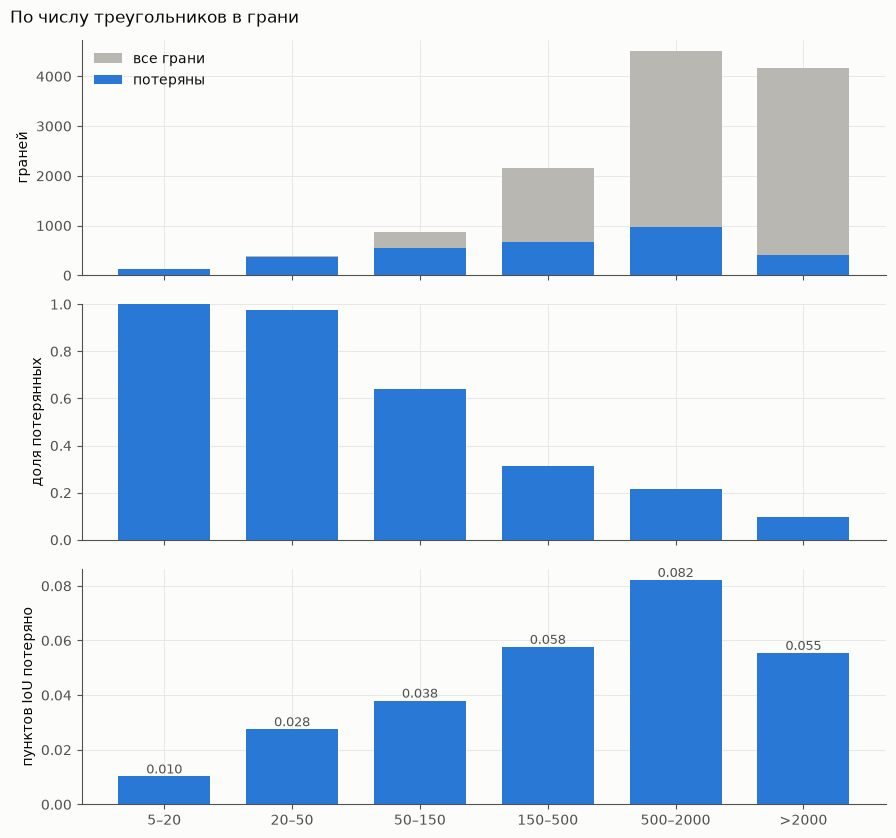

In [6]:
def three_panels(key, title):
    cats = [c for c in ORDER[key] if (col[key] == c).any()]
    masks = [col[key] == c for c in cats]
    x = np.arange(len(cats))
    fig, ax = plt.subplots(3, 1, figsize=(9, 8.5), sharex=True)
    ax[0].bar(x, [m.sum() for m in masks], 0.72, color=GRAY, label="все грани", linewidth=0)
    ax[0].bar(x, [col["lost"][m].sum() for m in masks], 0.72, color=PALETTE[0], label="потеряны", linewidth=0)
    ax[0].set_ylabel("граней"); ax[0].legend(frameon=False)
    ax[1].bar(x, [col["lost"][m].mean() for m in masks], 0.72, color=PALETTE[0], linewidth=0)
    ax[1].set_ylabel("доля потерянных"); ax[1].set_ylim(0, 1)
    d = [col["deficit"][m].sum() for m in masks]
    ax[2].bar(x, d, 0.72, color=PALETTE[0], linewidth=0)
    ax[2].set_ylabel("пунктов IoU потеряно")
    for xi, v in zip(x, d):
        ax[2].annotate(f"{v:.3f}", (xi, v), ha="center", va="bottom", fontsize=9, color=INK2)
    ax[2].set_xticks(x, cats)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    plt.tight_layout(); plt.show()

three_panels("размер", "По числу треугольников в грани")

## По ширине грани в миллиметрах

Полуширина — радиус наибольшего круга, вписанного в грань, точно по B-Rep (README, «Узкие грани: ширина в мм и правило разметки»). У группы граней ступеньки — наибольшая из них. Детали без неё (Fusion) — «нет данных».

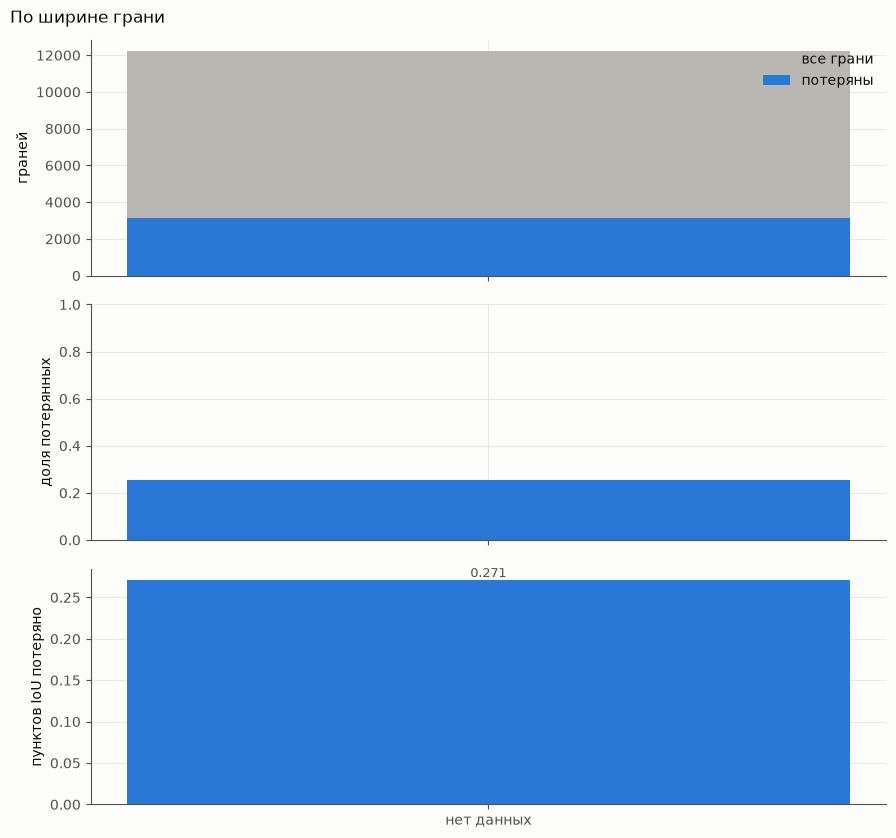

In [7]:
three_panels("ширина", "По ширине грани")

## По типу поверхности

Слева — доля потерянных, справа — сколько пунктов IoU теряется на гранях этого
типа. Снизу — как потеряны: поглощена соседом (протечка), раздроблена, прочее.

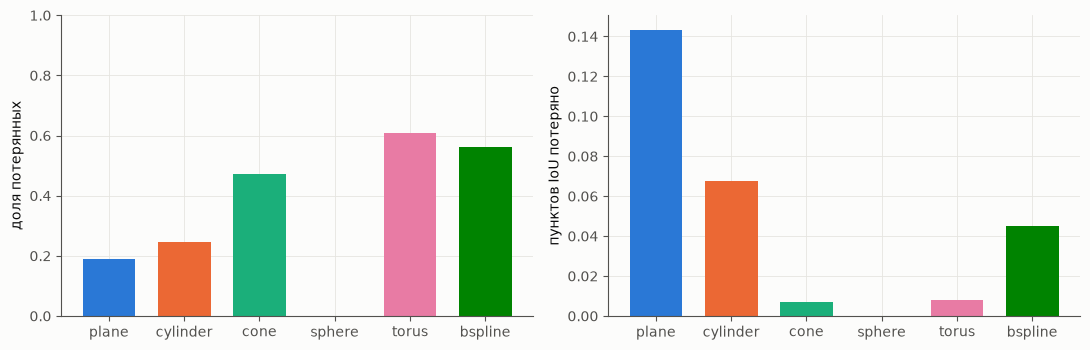

/home/daniil/curv_ai_segm/.venv/lib64/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/daniil/curv_ai_segm/.venv/lib64/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


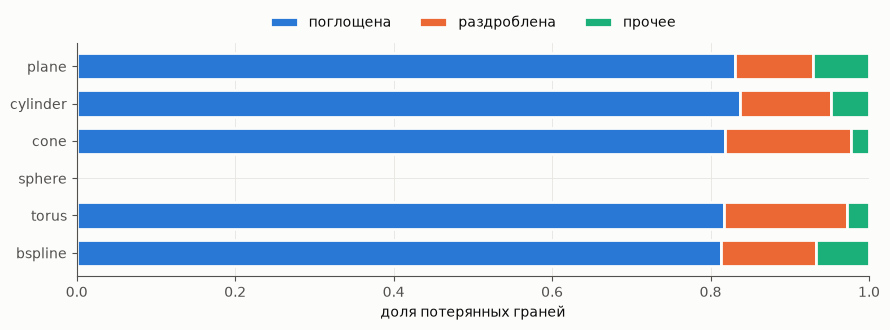

In [8]:
order = [t for t in TYPES if (col["type"] == t).any()]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(order, [col["lost"][col["type"] == t].mean() for t in order], 0.7, color=PALETTE[:len(order)], linewidth=0)
ax[0].set_ylabel("доля потерянных"); ax[0].set_ylim(0, 1)
ax[1].bar(order, [col["deficit"][col["type"] == t].sum() for t in order], 0.7, color=PALETTE[:len(order)], linewidth=0)
ax[1].set_ylabel("пунктов IoU потеряно")
plt.tight_layout(); plt.show()

fates = ["поглощена", "раздроблена", "прочее"]
lost = col["lost"]
fig, a = plt.subplots(figsize=(9, 3.4))
left = np.zeros(len(order))
for k, fate in enumerate(fates):
    share = np.array([np.mean(col["fate"][lost & (col["type"] == t)] == fate) for t in order])
    a.barh(order, share, left=left, color=PALETTE[k], label=fate, height=0.7, edgecolor="#fcfcfb", linewidth=2)
    left += share
a.set_xlim(0, 1); a.set_xlabel("доля потерянных граней"); a.invert_yaxis()
a.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(); plt.show()

## Кто кого поглощает

Строка — тип поглощённой грани, столбец — тип грани, чей кластер её съел. Число —
сколько таких поглощений. Диагональ — поглощения внутри одного типа (например,
плоскость плоскостью).

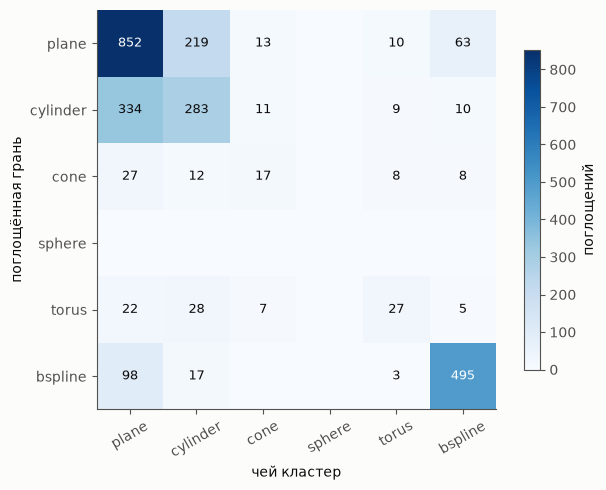

In [9]:
eat = col["fate"] == "поглощена"
m = np.array([[np.sum(eat & (col["type"] == a) & (col["eater_type"] == b)) for b in order] for a in order])
fig, a = plt.subplots(figsize=(6.5, 5))
im = a.imshow(m, cmap="Blues")
a.set_xticks(range(len(order)), order, rotation=30); a.set_yticks(range(len(order)), order)
a.set_xlabel("чей кластер"); a.set_ylabel("поглощённая грань"); a.grid(False)
for i in range(len(order)):
    for j in range(len(order)):
        if m[i, j]:
            a.text(j, i, m[i, j], ha="center", va="center", fontsize=9, color="white" if m[i, j] > m.max() * 0.55 else INK)
plt.colorbar(im, ax=a, shrink=0.8, label="поглощений")
plt.tight_layout(); plt.show()

## Касательный сосед и ширина

Доля потерянных граней с касательным соседом и без него, по ширине. Показывает,
что решает: ширина грани или гладкость перехода к соседу.

/tmp/ipykernel_3913204/1845562813.py:4: RuntimeWarning: Mean of empty slice
  v = [col["lost"][(col["ширина"] == c) & (col["стык"] == kind)].mean() for c in cats]
/home/daniil/curv_ai_segm/.venv/lib64/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


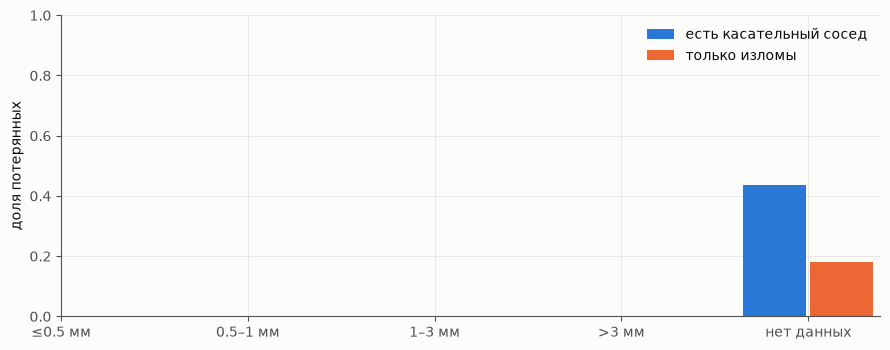

In [10]:
cats = ORDER["ширина"]; x = np.arange(len(cats)); w = 0.36
fig, a = plt.subplots(figsize=(9, 3.6))
for k, kind in enumerate(ORDER["стык"]):
    v = [col["lost"][(col["ширина"] == c) & (col["стык"] == kind)].mean() for c in cats]
    a.bar(x + (k - 0.5) * w, v, w * 0.94, color=PALETTE[k], label=kind, linewidth=0)
a.set_xticks(x, cats); a.set_ylim(0, 1); a.set_ylabel("доля потерянных")
a.legend(frameon=False)
plt.tight_layout(); plt.show()

## На каком этапе нарезки теряется грань

Водораздел — у грани не было своего региона с самого начала. Агломерация — регион
был, но его слили с соседом. Мелкие регионы — отданы соседу как слишком маленькие.

/home/daniil/curv_ai_segm/.venv/lib64/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/daniil/curv_ai_segm/.venv/lib64/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


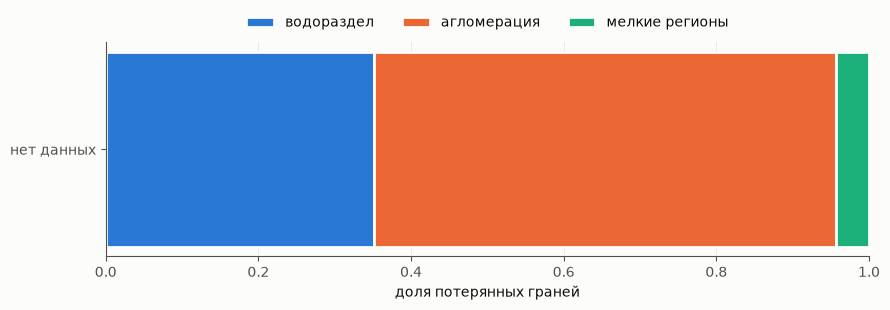

In [11]:
stages = ["водораздел", "агломерация", "мелкие регионы"]
cats = ORDER["ширина"]
fig, a = plt.subplots(figsize=(9, 3.2))
left = np.zeros(len(cats))
for k, stg in enumerate(stages):
    share = np.array([np.mean(col["stage"][lost & (col["ширина"] == c)] == stg) for c in cats])
    a.barh(cats, share, left=left, color=PALETTE[k], label=stg, height=0.7, edgecolor="#fcfcfb", linewidth=2)
    left += share
a.set_xlim(0, 1); a.set_xlabel("доля потерянных граней"); a.invert_yaxis()
a.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(); plt.show()

## По деталям

Слева — IoU детали против числа граней в ней. Детали со сломанным ремешем (граф
рабочего меша порван) выделены цветом. Справа — распределение IoU по деталям.

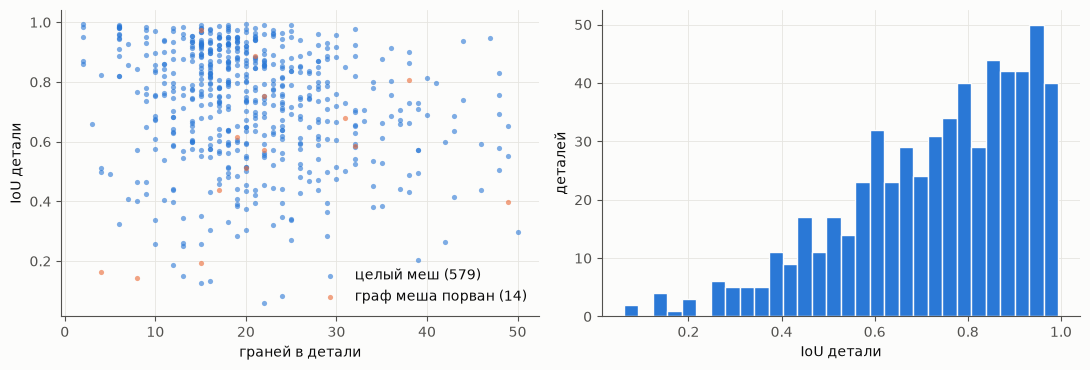

IoU: целый меш 0.733, граф порван 0.551; деталей с IoU > 0.9 — 22%, ниже 0.5 — 14%


In [12]:
uids = sorted(part_iou)
first = {}
for u, f, b in zip(col["uid"], col["faces_in_part"], col["broken"]):
    first.setdefault(u, (f, b))
piou = np.array([np.mean(part_iou[u]) for u in uids])
pfaces = np.array([first[u][0] for u in uids]); pbroken = np.array([first[u][1] for u in uids])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k, (flag, name) in enumerate(((False, "целый меш"), (True, "граф меша порван"))):
    m = pbroken == flag
    ax[0].scatter(pfaces[m], piou[m], s=14, color=PALETTE[k], alpha=0.6, linewidths=0, label=f"{name} ({m.sum()})")
ax[0].set_xlabel("граней в детали"); ax[0].set_ylabel("IoU детали"); ax[0].legend(frameon=False)
ax[1].hist(piou, bins=30, color=PALETTE[0], edgecolor="#fcfcfb", linewidth=1)
ax[1].set_xlabel("IoU детали"); ax[1].set_ylabel("деталей")
plt.tight_layout(); plt.show()
print(f"IoU: целый меш {piou[~pbroken].mean():.3f}, граф порван {piou[pbroken].mean():.3f}; "
      f"деталей с IoU > 0.9 — {np.mean(piou > 0.9):.0%}, ниже 0.5 — {np.mean(piou < 0.5):.0%}")

## Лоссы по эпохам

Train — среднее по всем шагам эпохи, val — после эпохи на `--val-limit` деталях
валидации. Лосс границ есть только у прогонов головы границ; шаг обучения
уменьшается по val-лоссу границ (у основной сети — по val triplet).

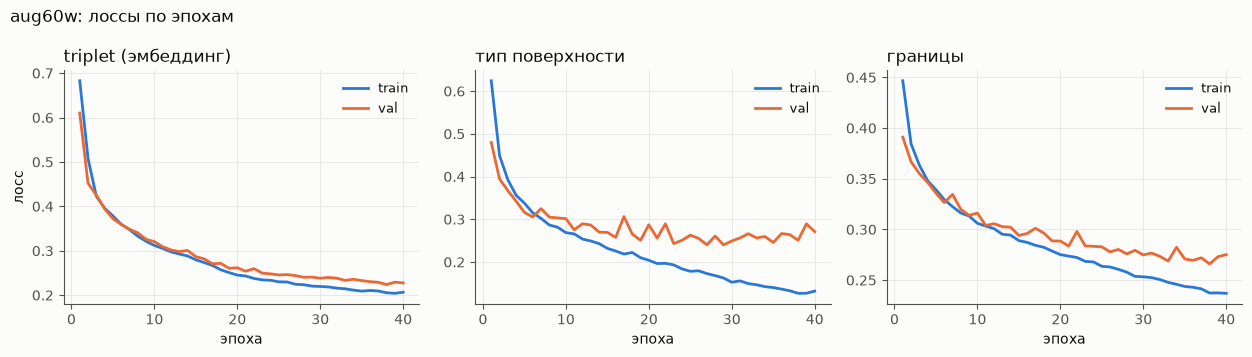

In [13]:
log = json.loads((ROOT / "runs" / RUN / "log.json").read_text())
epochs = [r["epoch"] for r in log]
LOSSES = [("triplet", "triplet (эмбеддинг)"), ("type", "тип поверхности"), ("edge", "границы")]
LOSSES = [(k, t) for k, t in LOSSES if f"val_{k}" in log[-1]]
fig, ax = plt.subplots(1, len(LOSSES), figsize=(4.2 * len(LOSSES), 3.6))
for a, (key, title) in zip(np.atleast_1d(ax), LOSSES):
    for k, split in enumerate(("train", "val")):
        v = [r.get(f"{split}_{key}", np.nan) for r in log]
        a.plot(epochs, v, color=PALETTE[k], lw=2, label=split)
    a.set_title(title, loc="left"); a.set_xlabel("эпоха")
    a.legend(frameon=False, fontsize=9)
np.atleast_1d(ax)[0].set_ylabel("лосс")
fig.suptitle(f"{RUN}: лоссы по эпохам", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.show()

## Рост IoU по эпохам

IoU и доля потерянных граней по типам и по полуширине после каждой эпохи
обучения. Пишутся в `log.json` прогона начиная с 2026-09-21; у прогонов раньше
этой даты разбивки нет. Для прогонов головы границ — по нарезке граф с вето
(`graphv_`), для основной сети — по mean-shift (`seg_`). Считается на
`--seg-limit` деталях валидации, по всем их граням вместе.

в log.json полуширина в старой кольцевой шкале — разбивка по ширине не показывается


/tmp/ipykernel_3913204/1262395201.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.set_xlabel("эпоха"); ax.legend(frameon=False, fontsize=9)


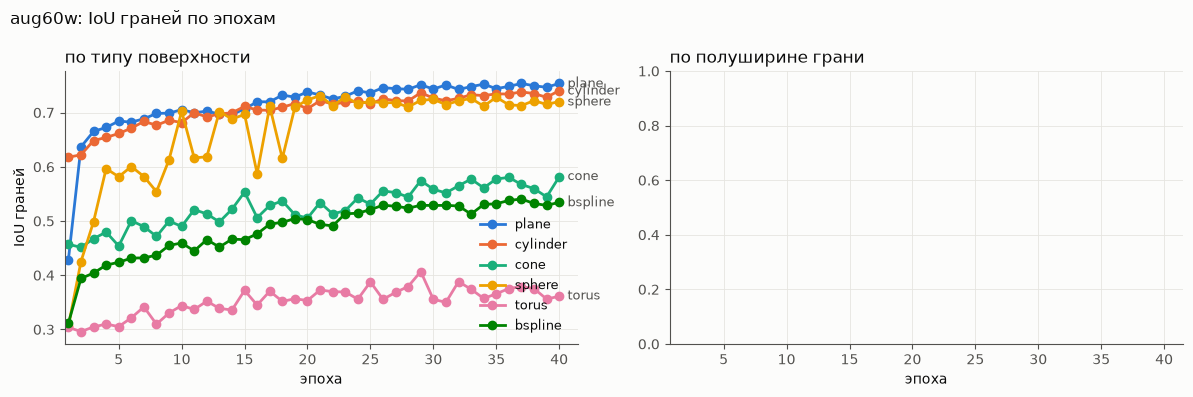

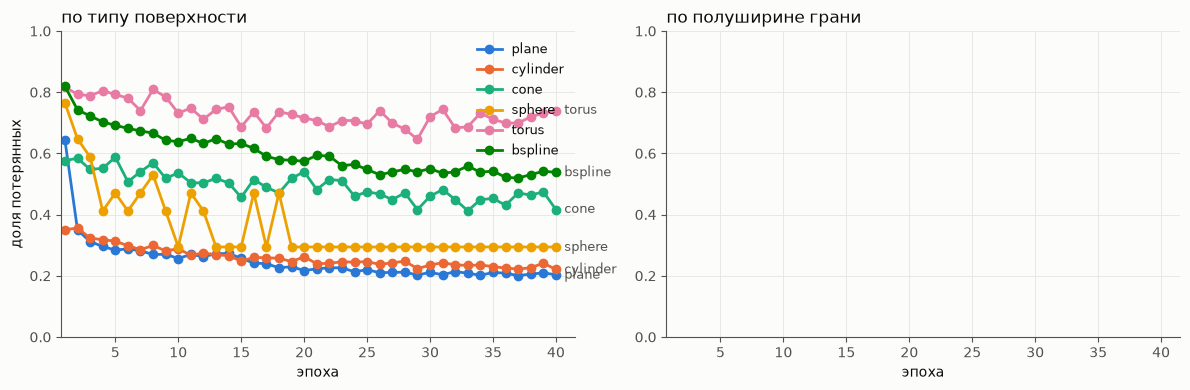

граней в оценке: {}


In [14]:
log = json.loads((ROOT / "runs" / RUN / "log.json").read_text())
prefix = "graphv_" if any(k.startswith("graphv_iou_") for k in log[-1]) else "seg_"
if not any(k.startswith(prefix + "iou_type_") for k in log[-1]):
    raise SystemExit(f"в log.json прогона {RUN} нет разбивки по эпохам: он запущен до 2026-09-21")
epochs = [r["epoch"] for r in log]
# Полосы точной полуширины; у прогонов до 2026-10-10 в log.json кольцевая шкала, её полосы не рисуются.
WIDTHS = ["le0.5", "0.5-1", "1-3", "gt3"]
WIDTH_LABEL = {"le0.5": "≤0.5 мм", "0.5-1": "0.5–1 мм", "1-3": "1–3 мм", "gt3": ">3 мм"}
if not any(f"{prefix}iou_width_le0.5" in r for r in log):
    print("в log.json полуширина в старой кольцевой шкале — разбивка по ширине не показывается")
    WIDTHS = []
BLUES = ["#a8c8f0", "#6ea3e3", "#2a78d6", "#154a8f"]          # последовательная шкала: уже -> шире

def curves(ax, keys, labels, colors, what):
    for key, label, color in zip(keys, labels, colors):
        v = [r.get(f"{prefix}{what}_{key}", np.nan) for r in log]
        if np.all(np.isnan(v)): continue
        ax.plot(epochs, v, color=color, lw=2, marker="o", ms=6, label=label)
        ax.annotate(label, (epochs[-1], v[-1]), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=9, color=INK2)
    ax.set_xlabel("эпоха"); ax.legend(frameon=False, fontsize=9)

types = [t for t in TYPES if any(f"{prefix}iou_type_{t}" in r for r in log)]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
curves(ax[0], types, types, PALETTE, "iou_type"); ax[0].set_ylabel("IoU граней"); ax[0].set_title("по типу поверхности", loc="left")
curves(ax[1], WIDTHS, [WIDTH_LABEL[w] for w in WIDTHS], BLUES, "iou_width"); ax[1].set_title("по полуширине грани", loc="left")
for a in ax: a.set_xlim(epochs[0] - 0.3, epochs[-1] + 1.5)
fig.suptitle(f"{RUN}: IoU граней по эпохам", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
curves(ax[0], types, types, PALETTE, "lost_type"); ax[0].set_ylabel("доля потерянных"); ax[0].set_title("по типу поверхности", loc="left")
curves(ax[1], WIDTHS, [WIDTH_LABEL[w] for w in WIDTHS], BLUES, "lost_width"); ax[1].set_title("по полуширине грани", loc="left")
for a in ax: a.set_xlim(epochs[0] - 0.3, epochs[-1] + 1.5); a.set_ylim(0, 1)
plt.tight_layout(); plt.show()

print("граней в оценке:", {WIDTH_LABEL[w]: log[-1].get(f"{prefix}n_width_{w}") for w in WIDTHS})